       Month  Temperature  Holidays  Promotion  Sales
0 2019-01-01         15.5         3          0  158.0
1 2019-02-01         19.9         2          0  158.0
2 2019-03-01         24.3         6          0  174.0
3 2019-04-01         26.5         4          0  171.0
4 2019-05-01         23.4         5          0  184.0


C:\Users\EduMain\AppData\Local\Temp\ipykernel_10212\1361922669.py:50: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\EduMain\.conda\envs\TFWork\lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


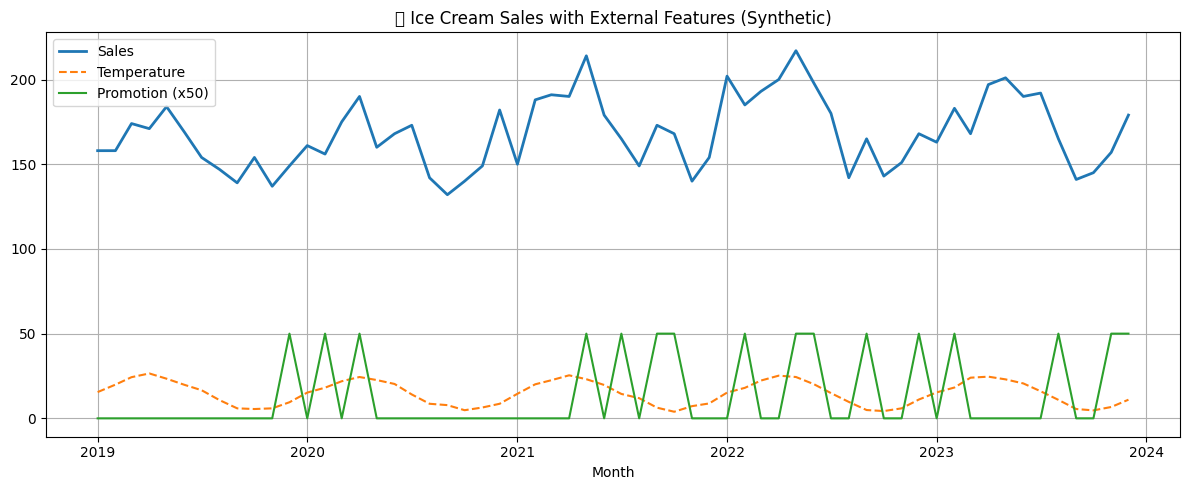

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 시드 고정
np.random.seed(0)

# 기간: 2019년 1월 ~ 2023년 12월 (60개월)
dates = pd.date_range(start="2019-01-01", end="2023-12-01", freq='MS')
n = len(dates)

# ------------------------------------------------------------------
# 1. 평균 기온 (여름에 높고 겨울에 낮은 계절성 반영)
#    temperature = 15 + 10 * sin(2π * 월번호 / 12) + 잡음
#    - 15 : 기온의 "평균 높이"(중심선). 사인파는 -1~+1 사이를 오가므로
#           15를 더해 기온이 15도 근처에서 위아래로 움직이게 한다.
#    - 10 : 사인파의 "진폭"(흔들리는 폭). 15 ± 10 이므로 기온이 대략 5~25도 범위가 된다.
#    - np.arange(n) : 0, 1, 2, ..., 59 (월 번호. 첫 달 2019-01이 0)
#    - 2 * np.pi * 월번호 / 12 : 12개월(1년)이 지나면 사인파가 정확히 한 바퀴(2π)를 돌게 하는 각도.
#                                즉 주기 = 12개월이라 매년 같은 패턴이 반복된다.
#    - np.random.normal(0, 1, n) : 평균 0, 표준편차 1인 정규분포 잡음 n개.
#                                  실제 기온처럼 해마다 조금씩 들쭉날쭉하게 만든다.
#    * 참고: 월번호 0이 1월이라 sin의 최고점은 3번째 달 근처(4월), 최저점은 9번째 달 근처(10월)다.
#            실제 한국 기후(8월 최고)와는 어긋난 "가짜 데이터"이니 그대로 믿지 말 것.
# ------------------------------------------------------------------
temperature = 15 + 10 * np.sin(2 * np.pi * np.arange(n) / 12) + np.random.normal(0, 1, n)

# ------------------------------------------------------------------
# 2. 휴일 수 (월별 휴일 일수)
#    np.random.randint(2, 7, n) : 2 이상 7 "미만"의 정수, 즉 2,3,4,5,6 중에서
#                                 무작위로 n(=60)개를 뽑는다. (끝값 7은 포함되지 않음)
#    - 평균은 (2+6)/2 = 4일, 주석의 "평균 4일, 2~6일"이 이 뜻이다.
# ------------------------------------------------------------------
holidays = np.random.randint(2, 7, n)

# ------------------------------------------------------------------
# 3. 프로모션 여부 (월별 0 또는 1)
#    np.random.choice([0, 1], size=n, p=[0.7, 0.3])
#    - [0, 1]    : 뽑을 후보. 0 = 프로모션 없음, 1 = 프로모션 있음
#    - size=n    : 60개월치를 뽑는다
#    - p=[0.7, 0.3] : 각 후보의 확률. 0이 나올 확률 70%, 1이 나올 확률 30%
#                     (60개월 중 평균 약 18개월이 프로모션 달)
# ------------------------------------------------------------------
promotion = np.random.choice([0, 1], size=n, p=[0.7, 0.3])

# ------------------------------------------------------------------
# 4. 판매량 (예측하려는 정답, 타겟)
#    sales = base + 기온 효과 + 휴일 효과 + 프로모션 효과 + 잡음
#    "기온/휴일/프로모션이 이만큼 영향을 준다"고 우리가 정해 놓고 만든 식이다.
#    나중에 RNN이 이 관계를 데이터만 보고 알아맞히는지 확인하려는 용도다.
#
#    (a) 기본 트렌드(base)
#        base = 100 + np.linspace(0, 30, n)
#        - 100 : 기본 판매량(다른 조건이 없을 때의 출발점)
#        - np.linspace(0, 30, n) : 0에서 30까지 n(=60)개를 같은 간격으로 늘어놓은 값.
#                                  그래서 base는 100에서 시작해 130까지 서서히 올라가는 우상향 추세다.
#        * 주석은 "연간 5씩 증가"라고 되어 있지만 계산해 보면 5년(60개월)에 30 증가이므로
#          실제로는 연간 약 6씩 증가한다.
#
#    (b) 영향 계수(= 가중치. 값이 클수록 그 요인이 판매량을 더 크게 움직인다)
#        - temperature * 2.5 : 기온이 1도 오르면 판매량 2.5 증가 (아이스크림이니 더우면 더 팔림)
#        - holidays * 3      : 휴일이 하루 늘면 판매량 3 증가
#        - promotion * 15    : 프로모션이 있는 달(1)은 판매량 +15, 없는 달(0)은 +0
#          (promotion이 0/1이라 "있으면 15를 더하는 스위치" 역할)
#
#    (c) np.random.normal(0, 10, n) : 평균 0, 표준편차 10인 잡음.
#        기온에 쓴 잡음(표준편차 1)보다 훨씬 커서, 판매량이 같은 조건에서도 ±10 정도 들쭉날쭉해진다.
#        현실의 설명 못 하는 변동을 흉내 낸 것이다.
#
#    np.round(sales, 0) : 소수점 0자리로 반올림해 판매량을 정수(실수형 150.0 꼴)로 만든다.
# ------------------------------------------------------------------
base = 100 + np.linspace(0, 30, n)
sales = base + (temperature * 2.5) + (holidays * 3) + (promotion * 15) + np.random.normal(0, 10, n)
sales = np.round(sales, 0)

# 데이터프레임 생성
df = pd.DataFrame({
    'Month': dates,
    'Temperature': np.round(temperature, 1),
    'Holidays': holidays,
    'Promotion': promotion,
    'Sales': sales
})

# 미리보기
print(df.head())

# 시각화
plt.figure(figsize=(12,5))
plt.plot(df['Month'], df['Sales'], label='Sales', linewidth=2)
plt.plot(df['Month'], df['Temperature'], label='Temperature', linestyle='--')
plt.plot(df['Month'], df['Promotion'] * 50, label='Promotion (x50)')
plt.title("📊 Ice Cream Sales with External Features (Synthetic)")
plt.xlabel("Month")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


## 이 데이터의 숫자(15, 10, 2.5 등)는 어디서 나온 걸까?

**결론: 실제 기상·판매 자료에서 구한 값이 아니라, 코드를 쓴 사람이 "그럴듯하게" 임의로 정한 값이다.**
(강사님이 이 숫자를 고른 이유는 코드에 적혀 있지 않아 알 수 없다. 아래는 코드를 보고 한 추정이다.)

### 근거
- 이 데이터는 `Synthetic`(합성), 즉 연습용 가짜 데이터다. 15와 10이 어디서 나왔는지 설명하는 주석이 없다.
- 같은 코드의 다른 숫자도 모두 정해 놓고 쓴 값이다: 영향 계수 2.5, 3, 15 / 기본 판매량 100 / 증가폭 30 / 잡음 크기 1, 10.

### 그래도 "그럴듯해서" 골랐을 가능성
- `15 ± 10` → 기온이 약 5~25도. 겨울엔 쌀쌀하고 여름엔 덥다고 느낄 만한 범위다.
- 15, 10은 딱 떨어지는 값이라 쓰기 쉽고 그래프도 보기 좋다.
- 실제 한국과 맞춘 값은 아니다. 한국은 월평균 기온이 겨울 영하 몇 도에서 여름 20도대 중반까지 오가서 이 식보다 폭이 훨씬 넓다.

### 실습에서 중요한 것: 숫자보다 구조
목적은 RNN이 시계열 패턴을 학습하는지 보는 것이다. 그래서 다음 네 가지가 섞인 데이터가 필요하다.

| 구성 요소 | 코드 | 역할 |
|---|---|---|
| 계절성 | `sin` 항 | 12개월마다 반복되는 패턴 |
| 추세 | `linspace` 항 | 시간이 갈수록 서서히 증가 |
| 외부 요인 | 휴일, 프로모션 | 판매량에 영향을 주는 입력 특성 |
| 잡음 | `np.random.normal` | 설명할 수 없는 들쭉날쭉함 |

15를 20으로, 10을 8로 바꿔도 실습 취지는 같다. 값을 바꿔서 다시 실행하고 `Sales` 그래프가 어떻게 달라지는지 보면 각 숫자의 역할을 이해하기 좋다.

In [3]:
# CSV 파일로 저장
df.to_csv("ice_cream_sales_data.csv", index=False, encoding='utf-8-sig')
